# Customer Churn Prediction with a Tuned Neural Network

**Name:** Zaid
**Domain:** AI/ML Internship

In [1]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)

try:
    from IPython.display import display
except ImportError:  # plain-Python fallback
    display = print

warnings.filterwarnings("ignore")
np.random.seed(42)

# One consistent look for every chart: blue = stays, orange = churns
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#3B6EA8", "#E07B39"
PALETTE = {"No": BLUE, "Yes": ORANGE}

ModuleNotFoundError: No module named 'matplotlib'

## Task 1: Load, Explore & Clean the Data

In [ ]:
# Upload the Kaggle CSV when running in Colab (skipped if the file is already present)
CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(CSV):
    uploaded = files.upload()
    CSV = list(uploaded.keys())[0]

df = pd.read_csv(CSV)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Column types, missing values and number of unique values
pd.DataFrame({"dtype": df.dtypes.astype(str), "missing (NaN)": df.isna().sum(), "unique values": df.nunique()})

,dtype,missing (NaN),unique values
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


`TotalCharges` is stored as text (`object`), which usually means some entries are not valid numbers. Let's look for them.

In [ ]:
blank_mask = df["TotalCharges"].str.strip() == ""
print(f"Blank TotalCharges entries: {blank_mask.sum()}")
df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges entries: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**How I handle it:** every blank `TotalCharges` belongs to a customer with `tenure = 0`, i.e. a brand-new customer who has not been billed yet. Their true total is therefore **0**, so I convert the column to numeric and fill these blanks with 0 instead of dropping the rows (this keeps all 7,043 customers and is more accurate than filling with the mean). `customerID` is just a unique label with no predictive value, so it is dropped.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")

# Safety check: the only missing values must be the new customers with tenure == 0
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

df = df.drop(columns=["customerID"])
print("Duplicate rows:", df.duplicated().sum())
print("Remaining missing values:", int(df.isna().sum().sum()))
print("TotalCharges dtype:", df["TotalCharges"].dtype)

Duplicate rows: 22
Remaining missing values: 0
TotalCharges dtype: float64


### Is churn balanced?

       customers  percent
Churn                    
No          5174    73.46
Yes         1869    26.54


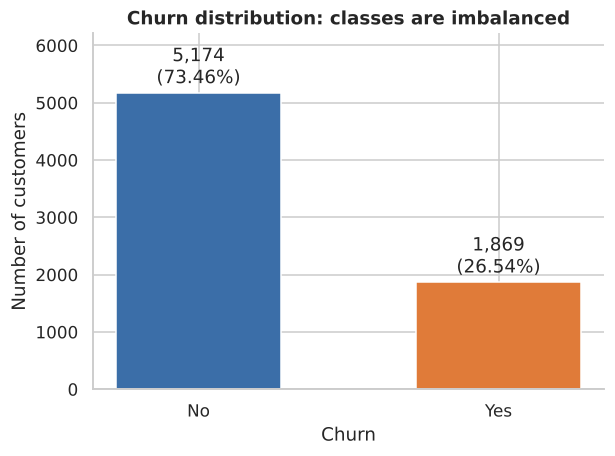

In [ ]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"customers": churn_counts, "percent": churn_pct}))

fig, ax = plt.subplots(figsize=(6, 4.2))
bars = ax.bar(churn_counts.index, churn_counts.values, color=[PALETTE[k] for k in churn_counts.index], width=0.55)
for bar, key in zip(bars, churn_counts.index):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 60,
            f"{int(bar.get_height()):,}\n({churn_pct[key]}%)", ha="center", va="bottom")
ax.set_title("Churn distribution: classes are imbalanced")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, churn_counts.max() * 1.2)
plt.show()

### How does churn relate to other features?

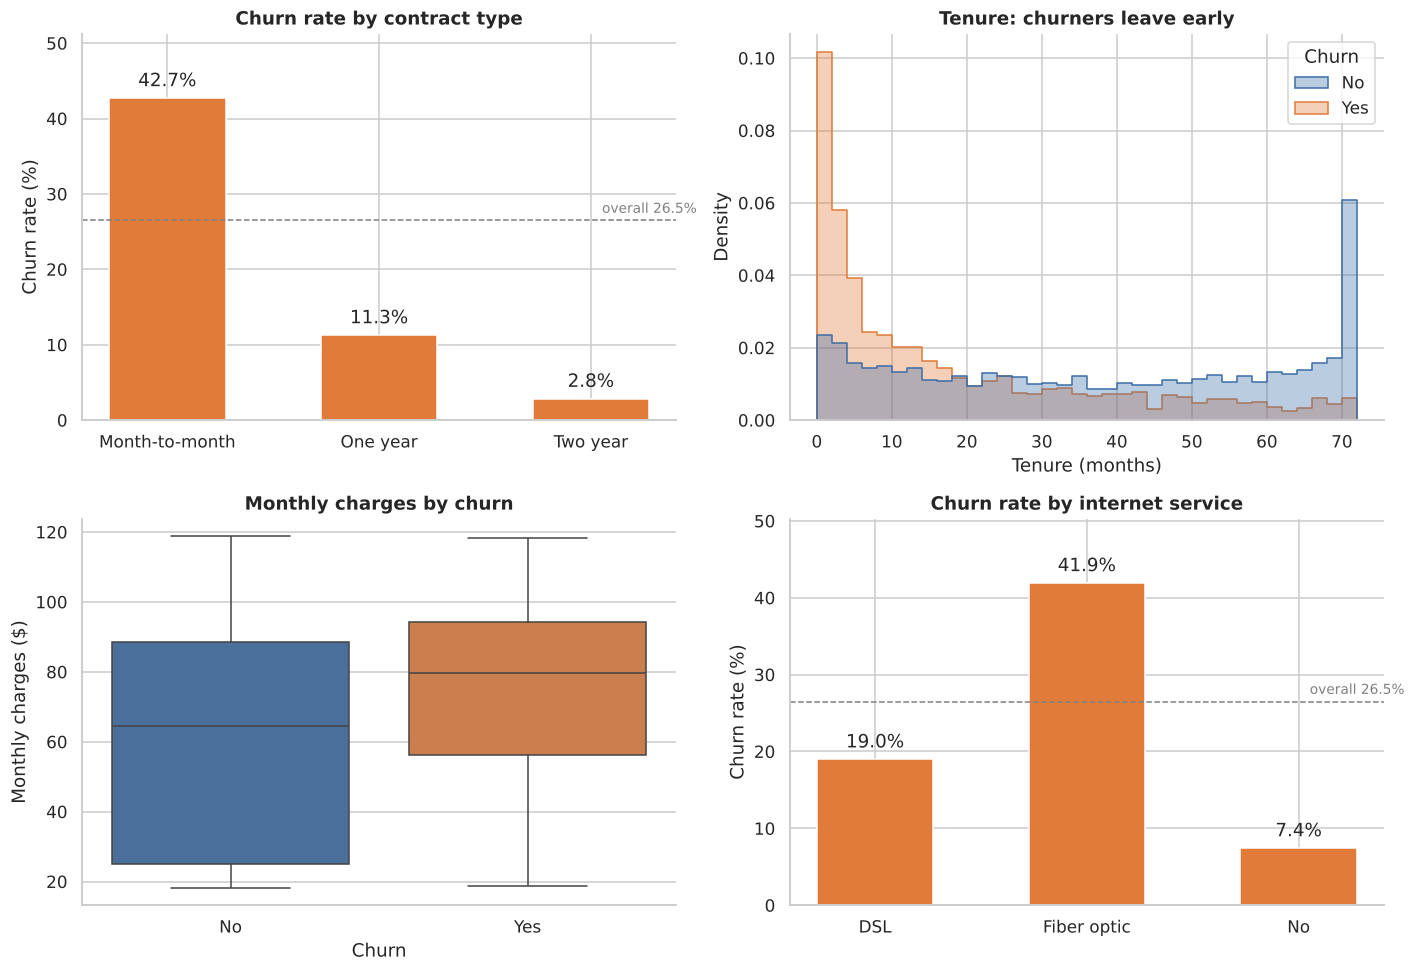

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

def rate_bars(ax, col, order, title):
    rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reindex(order)
    bars = ax.bar(order, rate.values, color=ORANGE, width=0.55)
    for bar, v in zip(bars, rate.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", va="bottom")
    ax.axhline(26.5, color="grey", linestyle="--", linewidth=1)
    ax.text(len(order) - 0.5, 27.5, "overall 26.5%", ha="right", color="grey", fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, rate.max() * 1.2)

# (a) contract type
rate_bars(axes[0, 0], "Contract", ["Month-to-month", "One year", "Two year"], "Churn rate by contract type")

# (b) tenure
sns.histplot(data=df, x="tenure", hue="Churn", palette=PALETTE, bins=36, stat="density",
             common_norm=False, element="step", alpha=0.35, ax=axes[0, 1])
axes[0, 1].set_title("Tenure: churners leave early")
axes[0, 1].set_xlabel("Tenure (months)")

# (c) monthly charges
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", palette=PALETTE, legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Monthly charges by churn")
axes[1, 0].set_ylabel("Monthly charges ($)")

# (d) internet service
rate_bars(axes[1, 1], "InternetService", ["DSL", "Fiber optic", "No"], "Churn rate by internet service")

plt.tight_layout()
plt.show()

**Observations**

- **Imbalance:** about 73.5% of customers stay and only 26.5% churn, so the classes are imbalanced (roughly 3 : 1).
- **Contract:** month-to-month customers churn far more than customers on one- or two-year contracts.
- **Tenure:** most churners leave within their first months; long-tenure customers rarely leave.
- **Charges and service:** churners pay more per month on average, and fiber-optic customers churn the most.

## Task 2: Preprocess for a Neural Network

**Encoding choices**

- **Binary columns** (`Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `gender`, and the Yes/No service add-ons) are mapped to **0/1**. For the add-on columns, "No internet service" / "No phone service" is merged into "No": that information is already carried by `InternetService` and `PhoneService`, so keeping a third category would only add redundant columns.
- **Multi-class nominal columns** (`InternetService`, `Contract`, `PaymentMethod`) use **one-hot encoding**. For example, `PaymentMethod` has no natural order, so integer (label) encoding would make the network assume that "Mailed check" = 1 is somehow "less" than "Electronic check" = 3. One-hot columns treat every payment method as equally distinct.
- **Numeric columns** (`tenure`, `MonthlyCharges`, `TotalCharges`) are standardised with `StandardScaler`. Neural networks train much better when inputs share a similar scale. The scaler is fitted **only on the training set** to avoid data leakage.

In [ ]:
YES_NO_COLS = ["Partner", "Dependents", "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
               "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling"]
ONE_HOT_COLS = ["InternetService", "Contract", "PaymentMethod"]
NUMERIC_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]

def encode_features(raw):
    """Deterministic encoding (no fitting), reused later for new customers."""
    d = raw.copy()
    d["gender"] = (d["gender"] == "Male").astype(int)
    for c in YES_NO_COLS:
        d[c] = d[c].replace({"No internet service": "No", "No phone service": "No"}).map({"Yes": 1, "No": 0})
    return pd.get_dummies(d, columns=ONE_HOT_COLS, dtype=int)

X_raw = df.drop(columns=["Churn"])
y = (df["Churn"] == "Yes").astype(int)

X = encode_features(X_raw)
print("Features after encoding:", X.shape[1])
X.head()

Features after encoding: 26


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,0,1,0,1,0,0,0,0,1,0


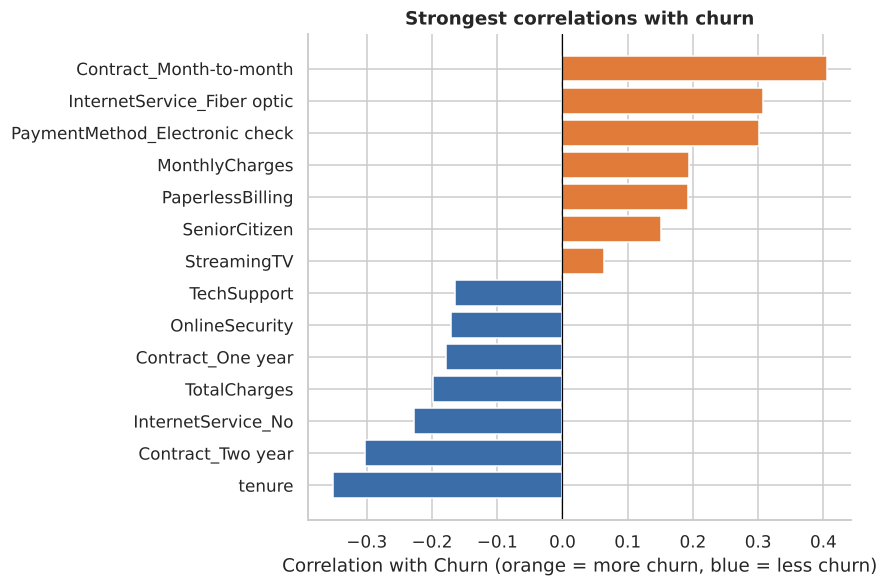

In [ ]:
# Which encoded features move together with churn? (correlation with the target)
corr = X.assign(Churn=y).corr()["Churn"].drop("Churn").sort_values()
top = pd.concat([corr.head(7), corr.tail(7)])

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=[BLUE if v < 0 else ORANGE for v in top.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Strongest correlations with churn")
ax.set_xlabel("Correlation with Churn (orange = more churn, blue = less churn)")
plt.tight_layout()
plt.show()

In [ ]:
# Stratified 80/20 split keeps the churn ratio the same in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numeric features: fit on TRAIN only, then apply to both
scaler = StandardScaler().fit(X_train[NUMERIC_COLS])
X_train, X_test = X_train.copy(), X_test.copy()
X_train[NUMERIC_COLS] = scaler.transform(X_train[NUMERIC_COLS])
X_test[NUMERIC_COLS] = scaler.transform(X_test[NUMERIC_COLS])

# Keep everything needed to preprocess a brand-new customer later (saved to JSON in Task 6)
prep = {"feature_columns": list(X.columns), "numeric_cols": NUMERIC_COLS,
        "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist()}

def transform_new(raw_df, prep):
    """Turn raw customer rows into the exact feature matrix the model was trained on."""
    d = encode_features(raw_df).reindex(columns=prep["feature_columns"], fill_value=0).astype(float)
    cols = prep["numeric_cols"]
    d[cols] = (d[cols] - np.array(prep["mean"])) / np.array(prep["scale"])
    return d.astype("float32")

X_train, X_test = X_train.astype("float32"), X_test.astype("float32")
y_train, y_test = y_train.astype("float32"), y_test.astype("float32")

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print(f"Churn rate  ->  train: {y_train.mean():.3f}   test: {y_test.mean():.3f}")

Train: (5634, 26)   Test: (1409, 26)
Churn rate  ->  train: 0.265   test: 0.265


## Task 3: Build & Train a Baseline Model

A simple Keras `Sequential` network: two hidden `Dense` layers (32 and 16 units, ReLU) and a single sigmoid output that gives the probability of churn. It uses the Adam optimizer and binary cross-entropy loss.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

tf.keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)

# Keras trains on plain NumPy arrays
X_train, X_test = np.asarray(X_train, dtype="float32"), np.asarray(X_test, dtype="float32")
y_train, y_test = np.asarray(y_train, dtype="float32"), np.asarray(y_test, dtype="float32")
print("Input shapes:", X_train.shape, X_test.shape)

In [ ]:
baseline = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
], name="baseline")

baseline.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
baseline.summary()

In [ ]:
hist_base = baseline.fit(X_train, y_train, validation_split=0.2, epochs=50, batch_size=32, verbose=0)

base_loss, base_acc = baseline.evaluate(X_test, y_test, verbose=0)
print(f"Baseline TEST accuracy: {base_acc:.4f}   (test loss: {base_loss:.4f})")

In [ ]:
def plot_history(hist, title):
    h = hist.history
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(h["loss"], color=BLUE, label="Training loss")
    axes[0].plot(h["val_loss"], color=ORANGE, label="Validation loss")
    axes[0].axvline(best_epoch - 1, color="grey", linestyle="--", linewidth=1, label=f"Lowest val loss (epoch {best_epoch})")
    axes[0].set_title(f"{title}: loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Binary cross-entropy"); axes[0].legend()

    axes[1].plot(h["accuracy"], color=BLUE, label="Training accuracy")
    axes[1].plot(h["val_accuracy"], color=ORANGE, label="Validation accuracy")
    axes[1].set_title(f"{title}: accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(hist_base, "Baseline")

**Reading the curves:** look at the point where the validation loss (orange) stops improving and turns upward while the training loss (blue) keeps falling. That widening gap is **overfitting**: the network starts to memorise the training data instead of learning patterns that generalise. This is exactly what the tuning techniques in Task 4 are meant to reduce.

## Task 4: Tune Your Model

I apply **four** techniques from Lab 15 to the same architecture idea:

| Technique | Why it helps here |
|---|---|
| **L2 regularization** (`1e-3`) | Penalises large weights, so the network cannot rely on a few extreme weights |
| **Batch Normalization** | Normalises each layer's inputs, which makes training faster and more stable |
| **Dropout** (`0.3`) | Randomly switches off neurons during training, reducing co-dependence and overfitting |
| **Early Stopping** (patience 10, restore best weights) | Stops training when validation loss stops improving and keeps the best epoch |

I also add `ReduceLROnPlateau`, which halves the learning rate when validation loss stalls.

In [ ]:
tf.keras.utils.set_random_seed(42)

def build_tuned(input_dim, l2=1e-3, dropout=0.3):
    return keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, kernel_regularizer=regularizers.l2(l2)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout),
        layers.Dense(32, kernel_regularizer=regularizers.l2(l2)),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ], name="tuned")

tuned = build_tuned(X_train.shape[1])
tuned.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
tuned.summary()

In [ ]:
early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
reduce_lr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)

hist_tuned = tuned.fit(X_train, y_train, validation_split=0.2, epochs=200, batch_size=32,
                       callbacks=[early_stop, reduce_lr], verbose=0)

print(f"Training stopped after {len(hist_tuned.history['loss'])} epochs (max was 200).")
tuned_loss, tuned_acc = tuned.evaluate(X_test, y_test, verbose=0)
print(f"Tuned TEST accuracy: {tuned_acc:.4f}   (test loss: {tuned_loss:.4f})")

plot_history(hist_tuned, "Tuned model")

### Before / after comparison

In [ ]:
def get_metrics(model, name):
    prob = model.predict(X_test, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1-score": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, prob),
            "Test loss": model.evaluate(X_test, y_test, verbose=0)[0]}

comparison = pd.DataFrame([get_metrics(baseline, "Baseline"), get_metrics(tuned, "Tuned")]).set_index("Model").round(4)
display(comparison)

# Grouped bar chart
plot_df = comparison[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].T
ax = plot_df.plot(kind="bar", figsize=(10, 4.8), color=[BLUE, ORANGE], width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.set_title("Baseline vs tuned model on the test set")
ax.set_ylabel("Score"); ax.set_ylim(0, 1.0); plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

delta = comparison.loc["Tuned", "Accuracy"] - comparison.loc["Baseline", "Accuracy"]
print(f"Accuracy change after tuning: {delta:+.4f} ({delta * 100:+.2f} percentage points)")

In [ ]:
# Validation-loss curves side by side: compare how each model behaves over the epochs
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(hist_base.history["val_loss"], color=BLUE, label="Baseline: validation loss")
ax.plot(hist_tuned.history["val_loss"], color=ORANGE, label="Tuned: validation loss")
ax.set_title("Validation loss: baseline vs tuned")
ax.set_xlabel("Epoch"); ax.set_ylabel("Binary cross-entropy"); ax.legend()
plt.tight_layout()
plt.show()

**Conclusion:** the exact before/after numbers are in the table above. Early Stopping guarantees that the final tuned model comes from the epoch with the lowest validation loss, and Dropout, L2 and Batch Normalization limit overfitting, so the tuned model is the more reliable one to use even when test accuracy moves only slightly (on this dataset, accuracy typically plateaus at around 80%).

## Task 5: Evaluate Properly

The best model is chosen by **F1-score on the churn class** (not accuracy), because catching churners is the actual goal.

In [ ]:
candidates = {"Baseline": baseline, "Tuned": tuned}
best_name = comparison["F1-score"].idxmax()
best_model = candidates[best_name]
print(f"Best model: {best_name}")

y_prob = best_model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification report (test set):\n")
print(classification_report(y_test, y_pred, target_names=["Stayed (0)", "Churned (1)"], digits=3))

print(f"Precision (churn): {precision_score(y_test, y_pred):.3f}")
print(f"Recall    (churn): {recall_score(y_test, y_pred):.3f}")
print(f"F1-score  (churn): {f1_score(y_test, y_pred):.3f}")

In [ ]:
cm = confusion_matrix(y_test, y_pred)
labels = ["Stayed", "Churned"]
annot = np.array([[f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.1f}% of row)" for j in range(2)] for i in range(2)])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, xticklabels=labels, yticklabels=labels,
            linewidths=1, linecolor="white", ax=axes[0])
axes[0].set_title(f"Confusion matrix ({best_name} model)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

for name, model, color in [("Baseline", baseline, BLUE), ("Tuned", tuned, ORANGE)]:
    p = model.predict(X_test, verbose=0).ravel()
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, color=color, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guess")
axes[1].set_title("ROC curve")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].legend()

plt.tight_layout()
plt.show()

majority_acc = (y_test == 0).mean()
print(f"Accuracy of a 'dummy' model that always predicts 'Stayed': {majority_acc:.3f}")
print(f"Accuracy of the {best_name} model: {accuracy_score(y_test, y_pred):.3f}")

**Would accuracy alone have been misleading?** Yes. About 73.5% of customers do not churn, so a useless model that always predicts "Stayed" would already score roughly 73% accuracy while finding **zero** churners. Because the classes are imbalanced, precision, recall and F1 on the churn class (and the confusion matrix) show how well the model actually catches customers who are about to leave.

## Task 6: Save & Predict

The best model is saved in the native Keras format (`.keras`). The scaling parameters and column order used in preprocessing are saved in a small JSON file so that a new customer can be transformed exactly like the training data.

In [ ]:
MODEL_PATH = "churn_model.keras"
PREP_PATH = "preprocessing.json"

best_model.save(MODEL_PATH)
with open(PREP_PATH, "w") as f:
    json.dump(prep, f)

print(f"Saved {best_name} model -> {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1024:.1f} KB)")
print(f"Saved preprocessing info -> {PREP_PATH}")

# Check that the model reloaded from disk gives identical predictions
reloaded = keras.models.load_model(MODEL_PATH)
print("Reloaded model matches original:", np.allclose(reloaded.predict(X_test, verbose=0),
                                                       best_model.predict(X_test, verbose=0), atol=1e-5))

In [ ]:
def predict_churn(customer, model_path=MODEL_PATH, prep_path=PREP_PATH, threshold=0.5):
    """Load the saved model and predict churn for one customer given as a dictionary of raw values."""
    model = keras.models.load_model(model_path)
    with open(prep_path) as f:
        saved_prep = json.load(f)
    X_new = transform_new(pd.DataFrame([customer]), saved_prep).values
    prob = float(model.predict(X_new, verbose=0)[0][0])
    return {"churn_probability": round(prob, 4),
            "prediction": "WILL CHURN" if prob >= threshold else "WILL STAY"}

# Hypothetical customer 1: new, month-to-month, fibre, no add-ons, pays by electronic check
customer_risky = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 2,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.5, "TotalCharges": 190.0,
}

# Hypothetical customer 2: long-term, two-year contract, DSL, with support services
customer_loyal = {
    "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes", "tenure": 60,
    "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "DSL",
    "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "Yes", "TechSupport": "Yes",
    "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Two year",
    "PaperlessBilling": "No", "PaymentMethod": "Bank transfer (automatic)",
    "MonthlyCharges": 65.0, "TotalCharges": 3900.0,
}

for name, cust in [("New month-to-month fibre customer", customer_risky),
                   ("Loyal two-year DSL customer", customer_loyal)]:
    result = predict_churn(cust)
    print(f"{name}: {result['prediction']}  (churn probability = {result['churn_probability']:.1%})")

In [ ]:
# Colab only: download the files so they can be pushed to GitHub
if IN_COLAB:
    for f in [MODEL_PATH, PREP_PATH]:
        files.download(f)

## Task 7: Short Answer: CNN vs. RNN

Use a **CNN** instead of a Dense network when the input has a spatial structure, such as the pixels of an image, because convolution filters reuse the same small set of weights across the whole image to detect local patterns (edges, textures, shapes) with far fewer parameters than a Dense layer; an example is classifying X-ray images as normal or pneumonia. Use an **RNN** (or LSTM/GRU) instead when the data is a sequence where order and earlier context matter, because it keeps a memory of previous steps, which a Dense network ignores; an example is predicting the next word in a sentence or forecasting tomorrow's electricity demand from the past weeks of readings. Customer churn here is a fixed table of independent features, so a Dense network is the right choice.